In [13]:
import sys
from pathlib import Path

import pandas as pd


def find_repo_root(start: Path) -> Path:
    """Walk up from ``start`` until the repository root is found."""
    for base in (start, *start.parents):
        if (base / "pyproject.toml").is_file() and (base / "data").is_dir():
            return base
    raise FileNotFoundError(
        f"Repository root not found from {start}. Open the notebook from inside the repository."
    )


# This notebook lives in notebooks/, so resolve paths from the repository root.
REPO_ROOT = find_repo_root(Path.cwd())

# The split lives in the C1 service. Make it importable even when the
# notebook runs on an interpreter where the workspace package is not installed.
SERVICE_SRC = REPO_ROOT / "services/c1-sensor-quality/src"
if str(SERVICE_SRC) not in sys.path:
    sys.path.insert(0, str(SERVICE_SRC))


DATA_FILE = REPO_ROOT / "data/processed/cleaned_predictive_maintenance_data.csv"
# DATA_FILE = REPO_ROOT / "data/raw/predictive_maintenance_data.csv"
MODEL_DIR = REPO_ROOT / "models/c1-sensor-quality"

df = pd.read_csv(DATA_FILE, parse_dates=["timestamp"], low_memory=False)
print(f"{DATA_FILE} -> {df.shape[0]:,} rows x {df.shape[1]} columns")

/mnt/D6A44CAEA44C92C3/Documents/documents Pierre/ecole/UTT/ISI/étranger/A26/cours/developing AI enabled systems/project/data/processed/cleaned_predictive_maintenance_data.csv -> 525,600 rows x 20 columns


In [14]:
df2 = df[df["anomaly_type"]!="missing_value"]

In [15]:
df2["anomaly_type"].value_counts()

anomaly_type
normal           522395
sensor_frozen      1068
sensor_spike       1061
Name: count, dtype: int64

In [16]:


def get_precision(x):
    return str(x)[::-1].find('.')

(df2["vibration"].apply(get_precision)<5).value_counts()

vibration
False    523456
True       1068
Name: count, dtype: int64

In [17]:
df2[df2["vibration"].apply(get_precision)<2]["anomaly_type"].value_counts()

anomaly_type
sensor_frozen    1068
Name: count, dtype: int64

here we see that we can definitely use this kind of threshold, and generalize it to every sensor types. only to detect sensor frozen

---

In [18]:
mode_medians = {
    "NORMAL": {
      "temperature": 52.56,
      "vibration": 4.54,
      "pressure": 96.59,
      "rpm": 1510.86,
      "power": 223.51
    },
    "HIGH_LOAD": {
      "temperature": 60.62,
      "vibration": 4.55,
      "pressure": 96.59,
      "rpm": 2210.58,
      "power": 343.47
    },
    "IDLE": {
      "temperature": 47.48,
      "vibration": 4.51,
      "pressure": 96.61,
      "rpm": 509.42,
      "power": 73.48
    },
    "OVERLOAD": {
      "temperature": 67.61,
      "vibration": 4.55,
      "pressure": 96.59,
      "rpm": 2609.89,
      "power": 473.47
    }
  }
MODE_SENSOR_SCALES = {
    "NORMAL": {
        "pressure": 2.396497499590686,
        "rpm": 25.186262879783143,
        "temperature": 11.068097286475194,
        "vibration": 2.413352730897005,
        "power": 15.766554474168501,
    },
    "HIGH_LOAD": {
        "pressure": 2.404953763971218,
        "rpm": 24.891443614401403,
        "temperature": 11.098892456082067,
        "vibration": 2.4163267382199516,
        "power": 15.800736615145281,
    },
    "IDLE": {
        "pressure": 2.3997126655362018,
        "rpm": 24.998563979466475,
        "temperature": 10.98101959960603,
        "vibration": 2.408662675919117,
        "power": 15.724157162087536,
    },
    "OVERLOAD": {
        "pressure": 2.3938877934387155,
        "rpm": 24.771198161615423,
        "temperature": 10.961150237244917,
        "vibration": 2.4167123624928104,
        "power": 15.746947681326466,
    },
}
SENSORS = ["pressure", "rpm", "temperature", "vibration", "power"]
import numpy as np


In [19]:
z_cols = [f"z_score_{sensor}" for sensor in SENSORS]
out = df2.copy()
out[z_cols] = np.nan
for mode, medians in mode_medians.items():
    mask = out["operating_mode"].astype(str) == mode
    median = pd.Series(medians).loc[SENSORS]
    scale = pd.Series(MODE_SENSOR_SCALES[mode]).loc[SENSORS]
    out.loc[mask, z_cols] = ((out.loc[mask, SENSORS] - median) / scale).to_numpy()

In [20]:
out

,timestamp,machine_id,operating_mode,temperature,vibration,pressure,rpm,power,anomaly,anomaly_type,...,maintenance_action,priority,concept_drift_active,quality_disposition,quality_flags,z_score_pressure,z_score_rpm,z_score_temperature,z_score_vibration,z_score_power
0,2012-01-14 00:00:00,M001,HIGH_LOAD,46.075260,1.646840,98.800597,2188.426973,316.167708,False,normal,...,align_motor,low,False,valid,none,0.919185,-0.889986,-1.310468,-1.201477,-1.727913
1,2012-01-14 01:00:00,M001,NORMAL,39.162895,1.250197,99.416209,1523.071068,201.667279,False,normal,...,align_motor,low,False,valid,none,1.179308,0.484830,-1.210425,-1.363167,-1.385383
2,2012-01-14 02:00:00,M001,HIGH_LOAD,42.957758,1.464074,99.556791,2265.053310,313.975128,False,normal,...,align_motor,low,False,valid,none,1.233616,2.188435,-1.591352,-1.277114,-1.866677
3,2012-01-14 03:00:00,M001,IDLE,31.526523,1.689659,99.721406,457.001901,50.063467,False,normal,...,align_motor,low,False,valid,none,1.296574,-2.096844,-1.452823,-1.170916,-1.489208
4,2012-01-14 04:00:00,M001,OVERLOAD,49.871989,1.127727,99.231099,2613.305245,449.423193,False,normal,...,align_motor,low,False,valid,none,1.103268,0.137872,-1.618262,-1.416086,-1.527077
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525595,2015-01-12 19:00:00,M020,NORMAL,71.508992,6.432024,94.136567,2016.177275,237.529540,False,normal,...,replace_valve,medium,True,valid,none,-1.023758,20.063210,1.712037,0.783981,0.889195
525596,2015-01-12 20:00:00,M020,NORMAL,74.857315,6.311347,94.301110,2029.063023,227.026160,False,normal,...,replace_valve,medium,True,valid,none,-0.955098,20.574828,2.014557,0.733977,0.223014
525597,2015-01-12 21:00:00,M020,NORMAL,73.018406,6.336043,93.629204,2035.018406,236.767941,False,normal,...,replace_valve,medium,True,valid,none,-1.235468,20.811281,1.848412,0.744211,0.840890
525598,2015-01-12 22:00:00,M020,HIGH_LOAD,80.456730,6.089872,94.157359,2993.251769,357.652712,False,normal,...,replace_valve,medium,True,valid,none,-1.011513,31.443406,1.787271,0.637278,0.897598


In [21]:
out[[f"z_score_{sensor}" for sensor in SENSORS]].head()


,z_score_pressure,z_score_rpm,z_score_temperature,z_score_vibration,z_score_power
0,0.919185,-0.889986,-1.310468,-1.201477,-1.727913
1,1.179308,0.484830,-1.210425,-1.363167,-1.385383
2,1.233616,2.188435,-1.591352,-1.277114,-1.866677
3,1.296574,-2.096844,-1.452823,-1.170916,-1.489208
4,1.103268,0.137872,-1.618262,-1.416086,-1.527077


In [22]:
out[[f"z_score_{sensor}" for sensor in SENSORS]].max(axis=1).head()


0    0.919185
1    1.179308
2    2.188435
3    1.296574
4    1.103268
dtype: float64

/tmp/ipykernel_63960/4065057969.py:34: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/mnt/D6A44CAEA44C92C3/Documents/documents Pierre/ecole/UTT/ISI/étranger/A26/cours/developing AI enabled systems/project/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


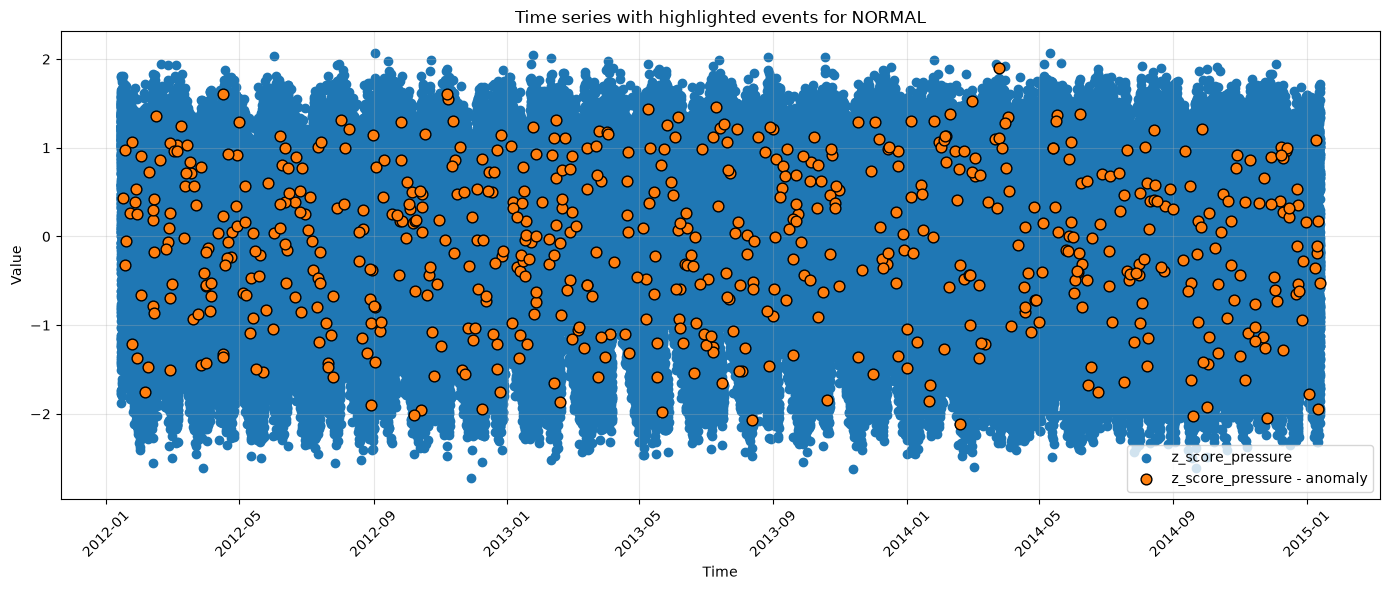

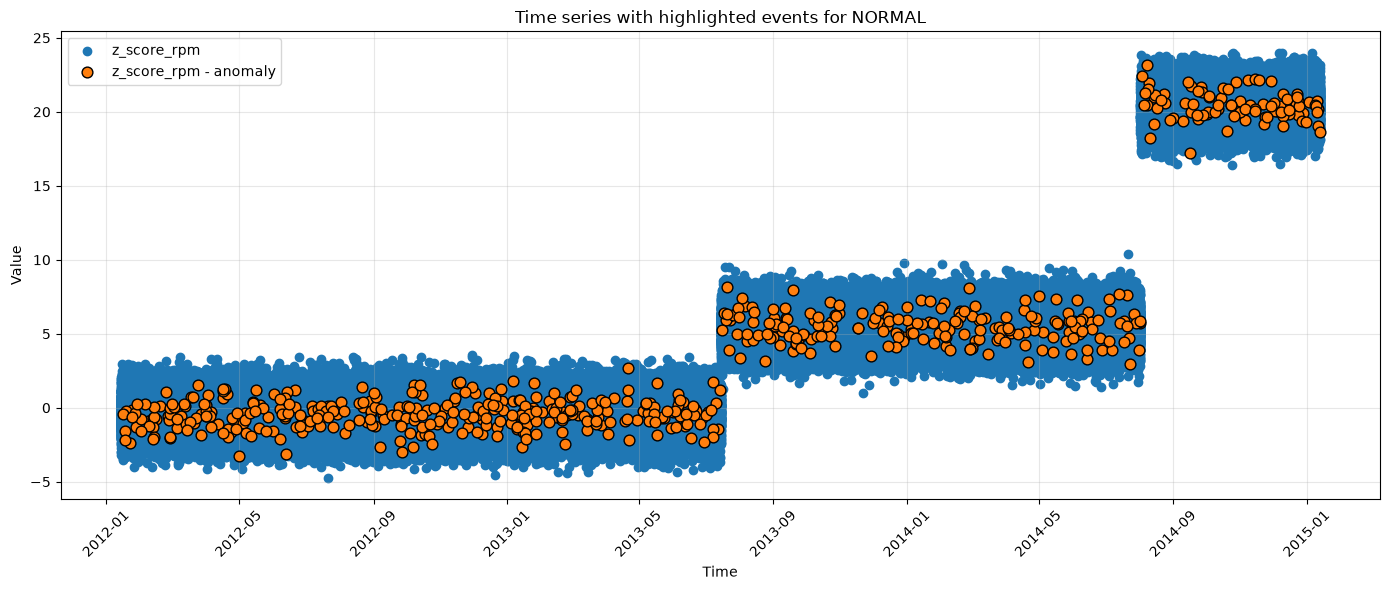

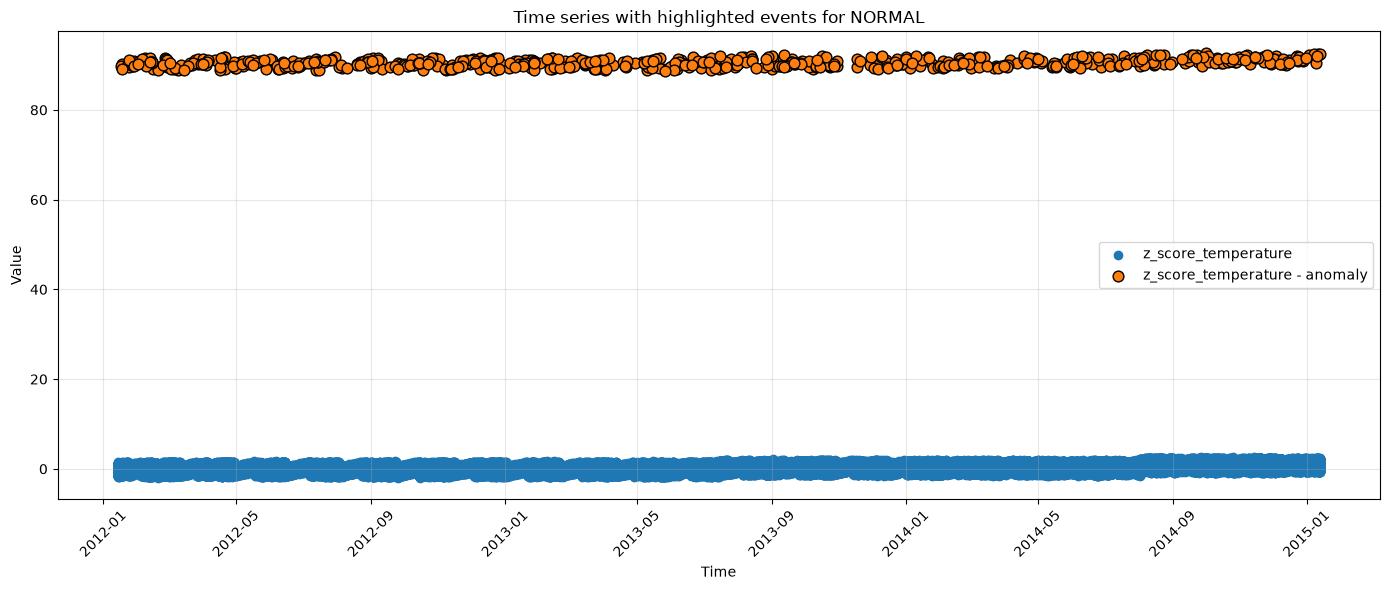

/tmp/ipykernel_63960/4065057969.py:34: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/mnt/D6A44CAEA44C92C3/Documents/documents Pierre/ecole/UTT/ISI/étranger/A26/cours/developing AI enabled systems/project/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


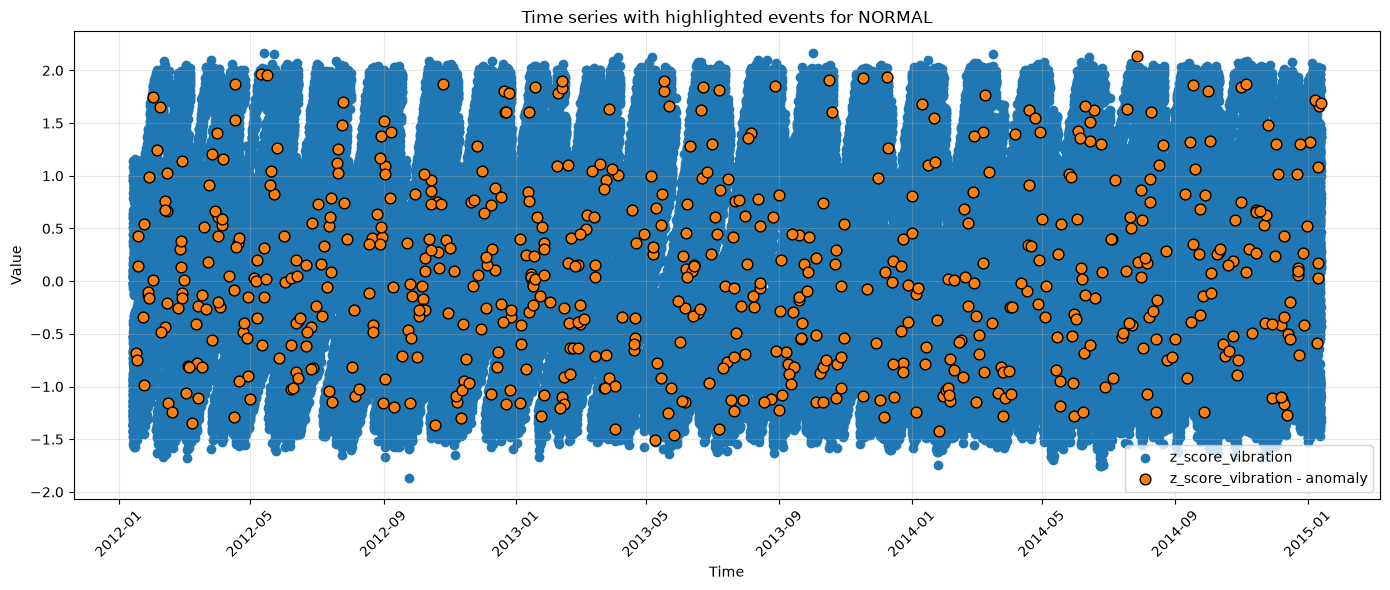

/tmp/ipykernel_63960/4065057969.py:34: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


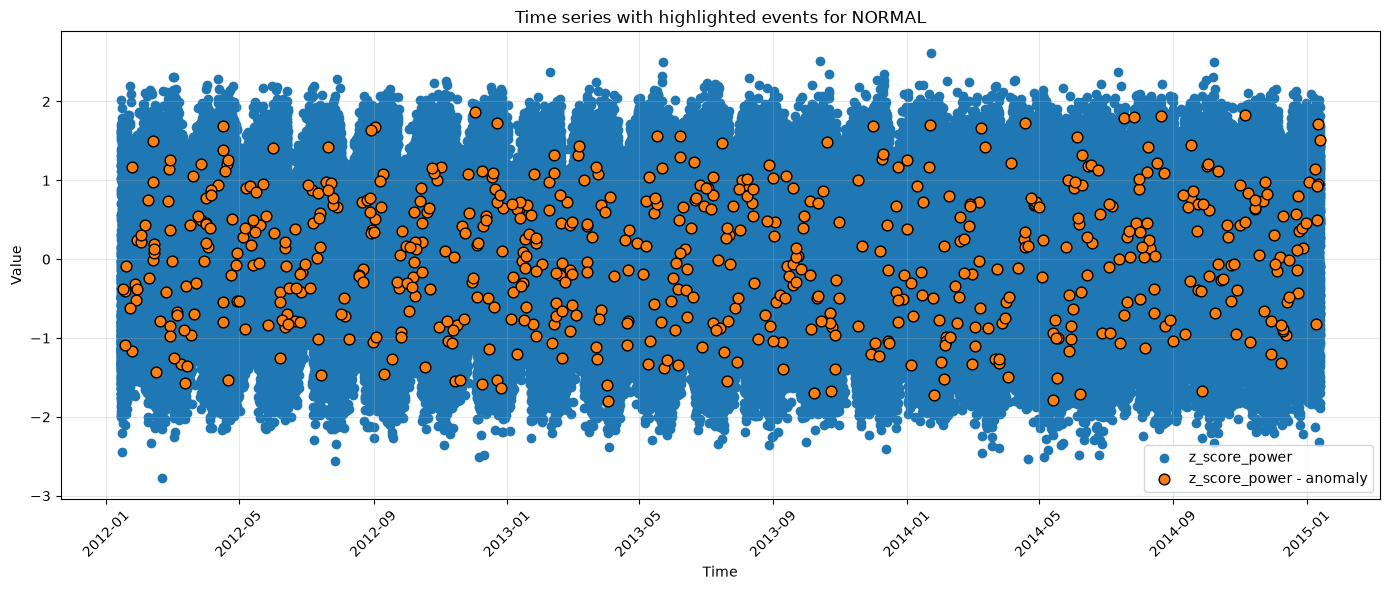

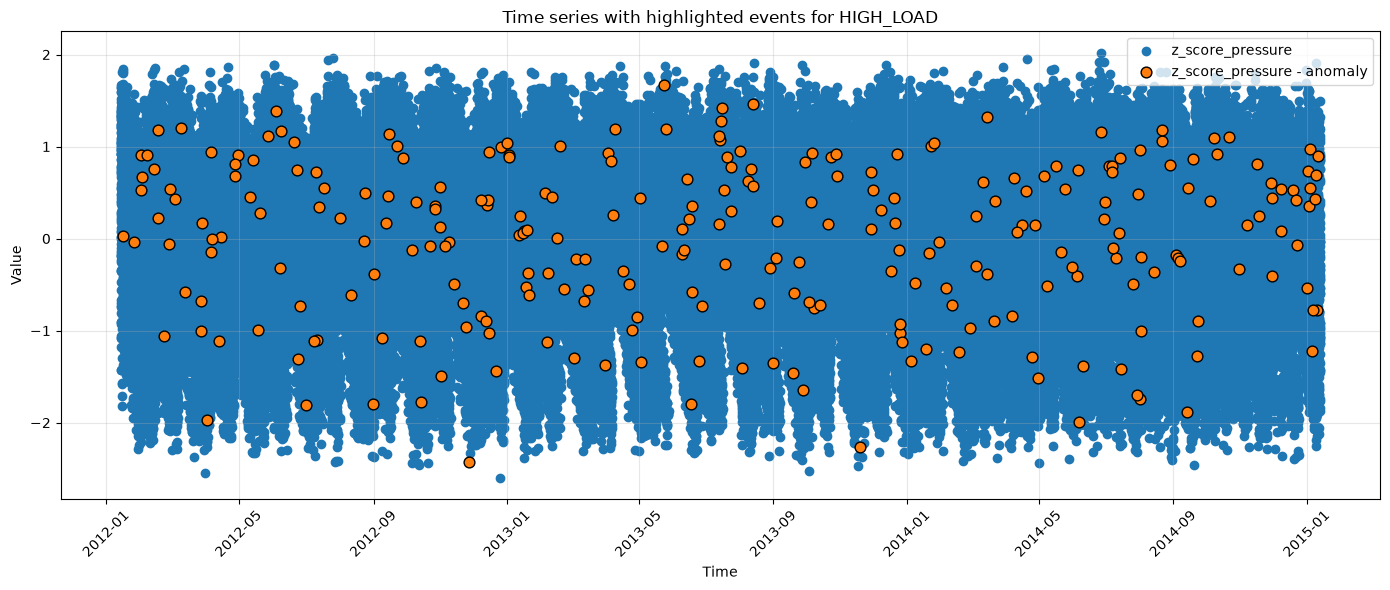

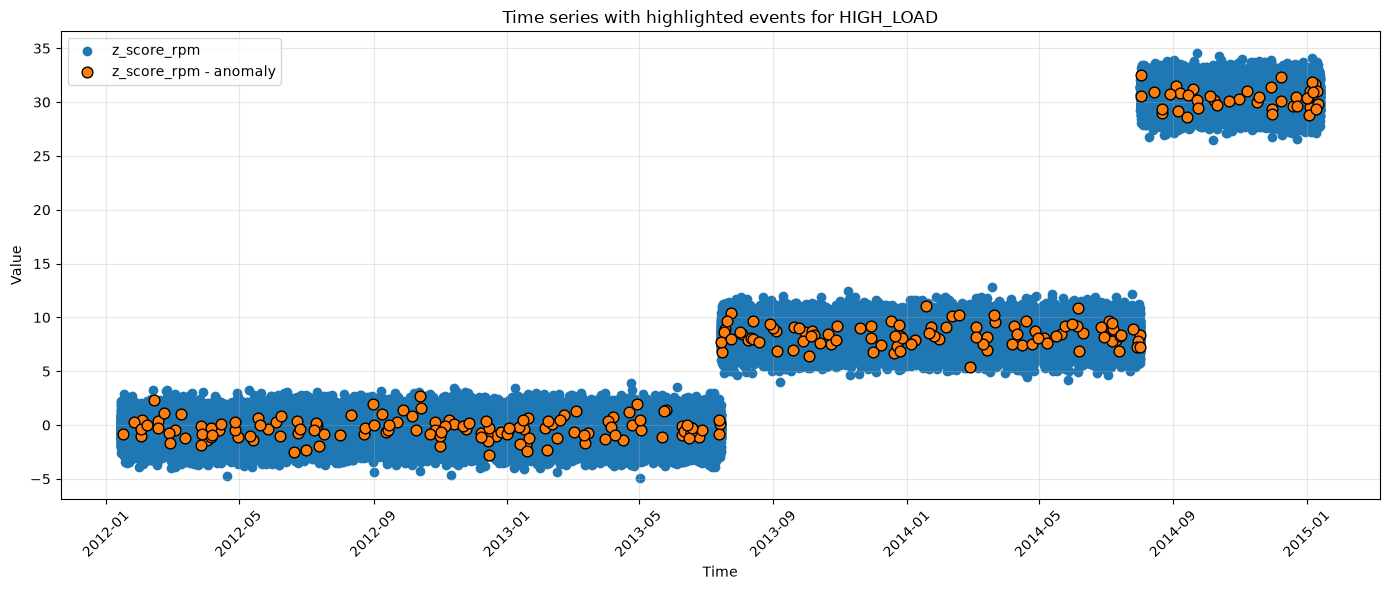

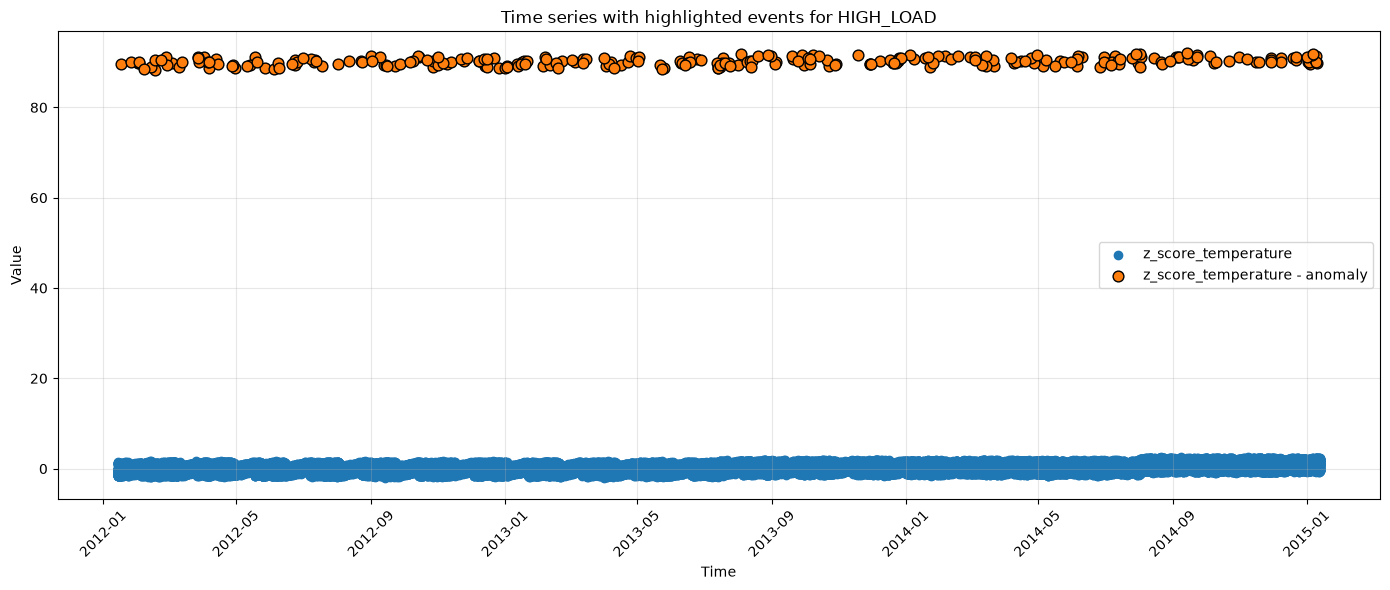

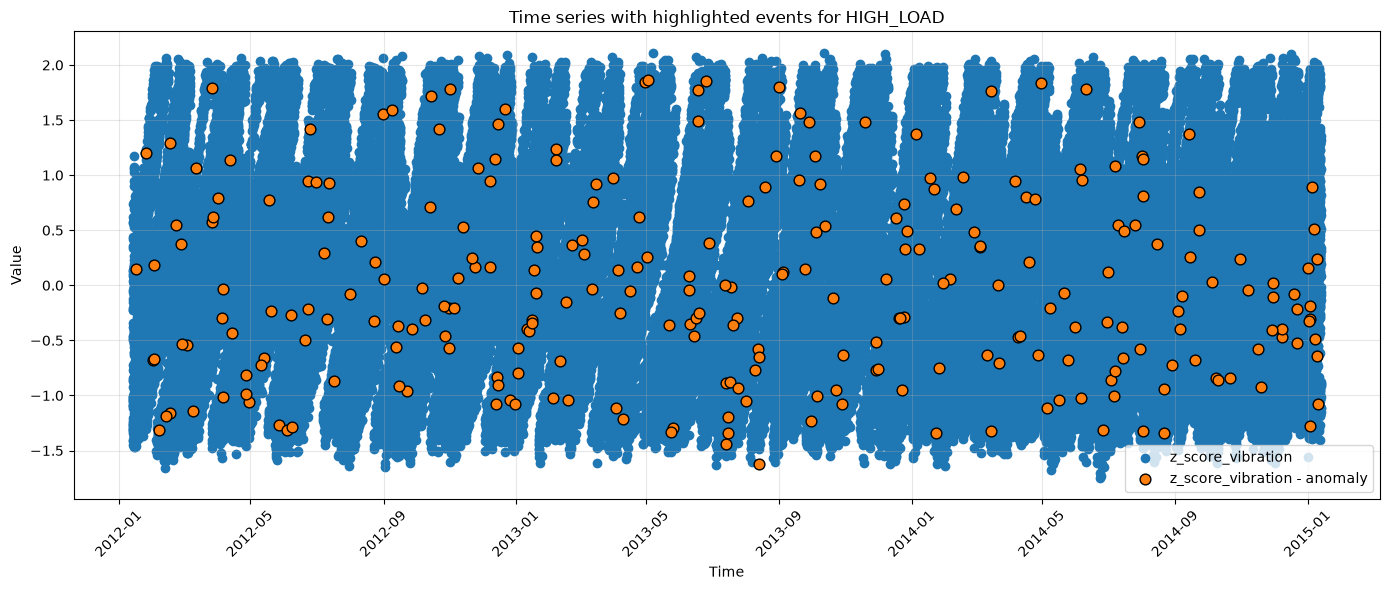

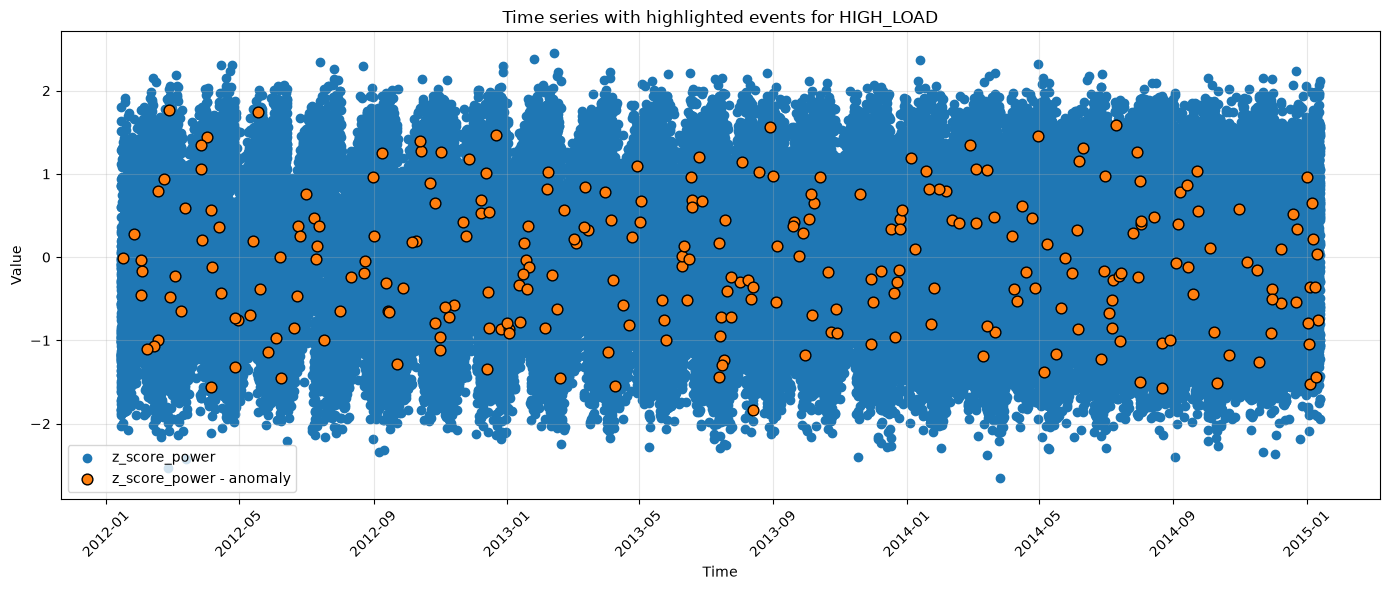

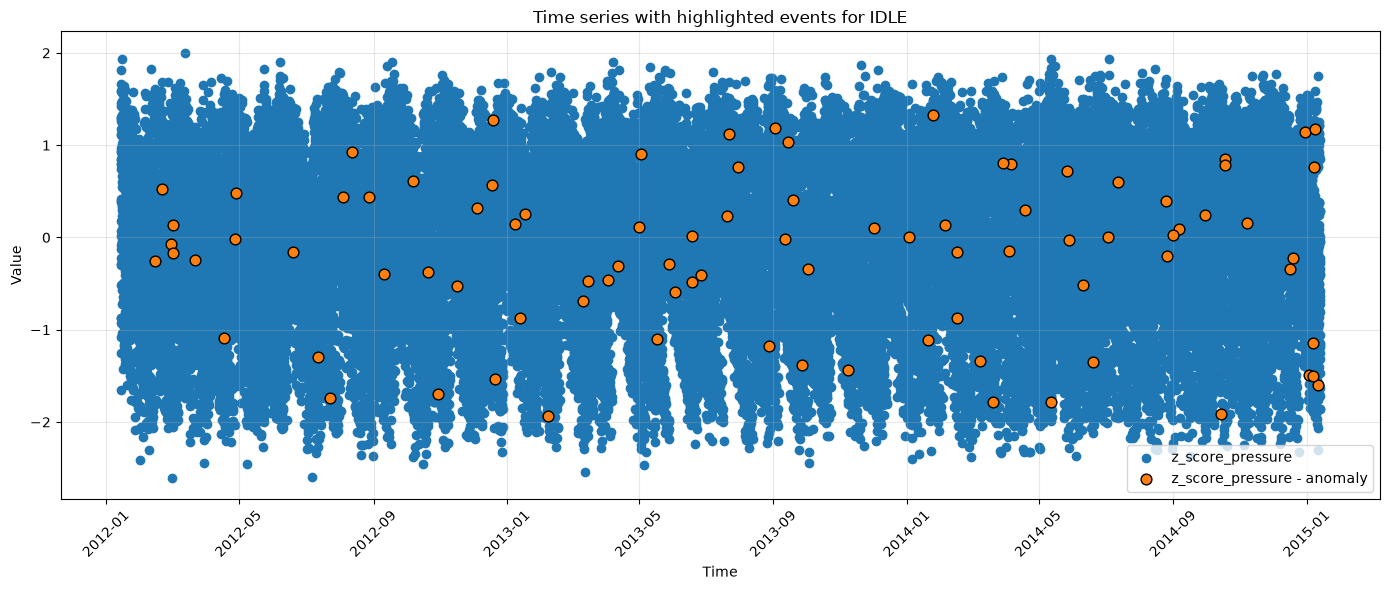

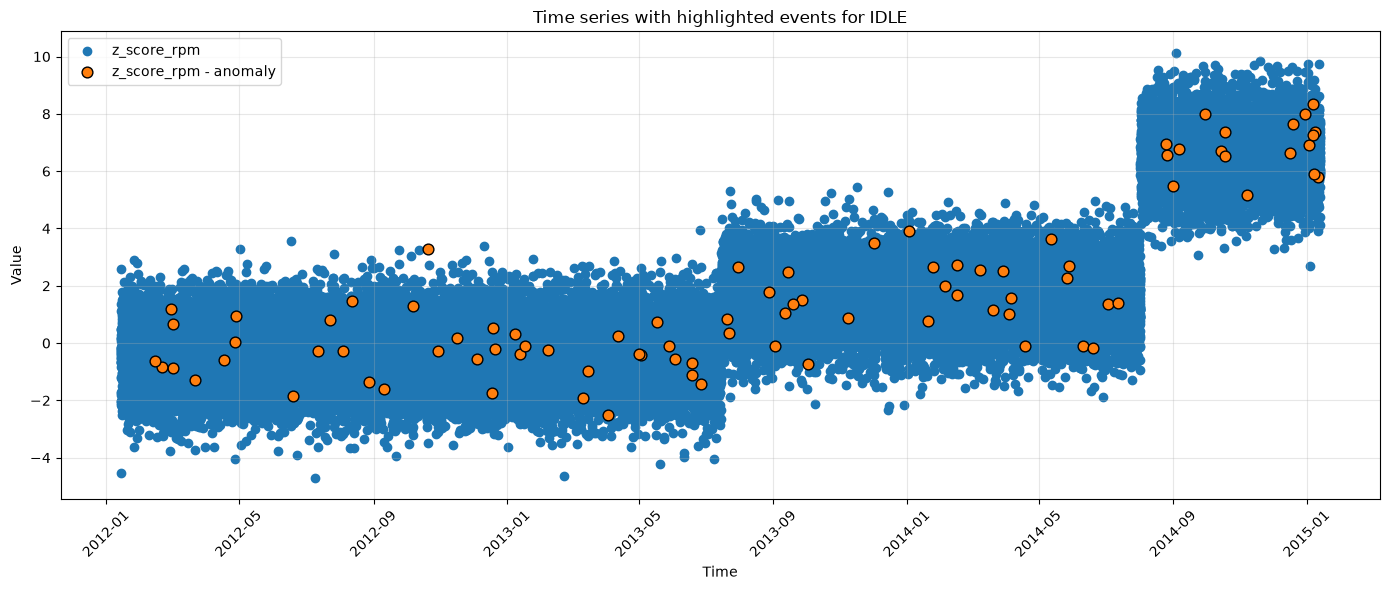

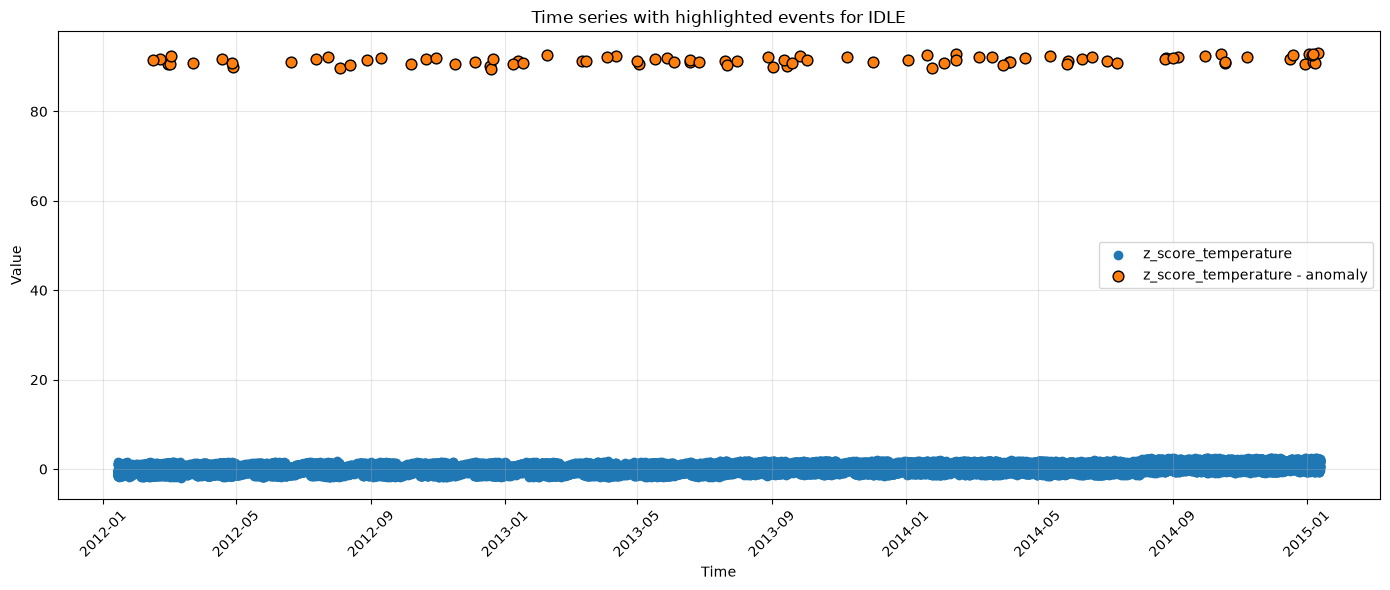

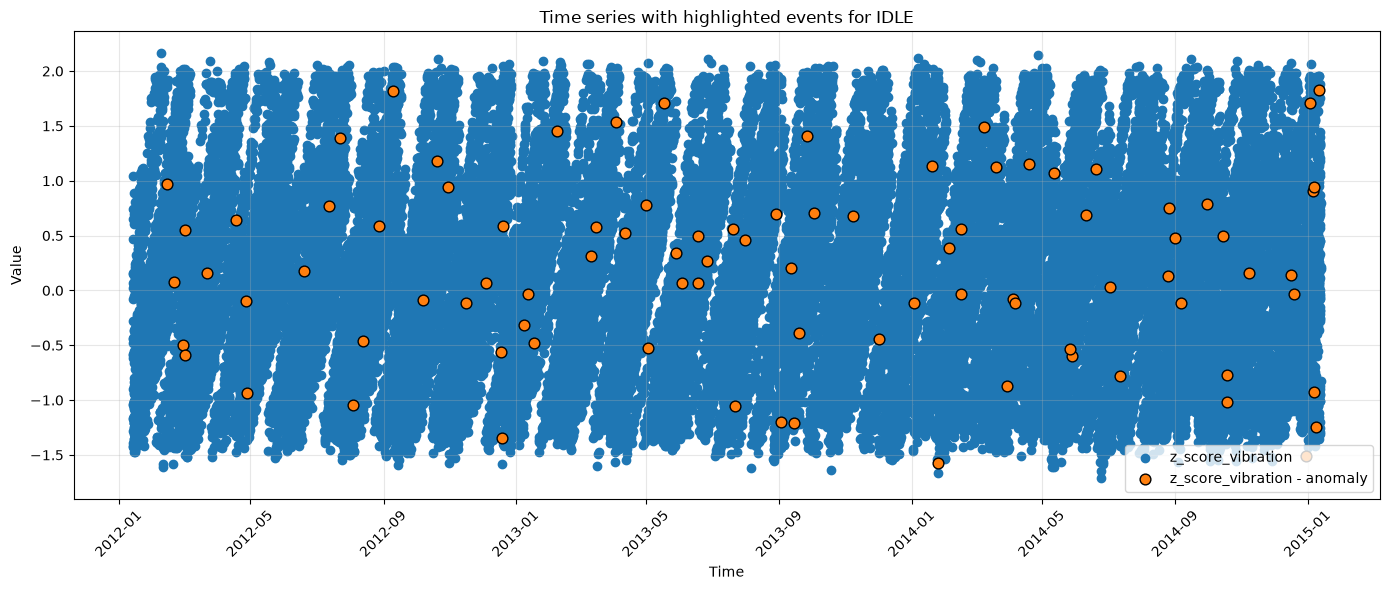

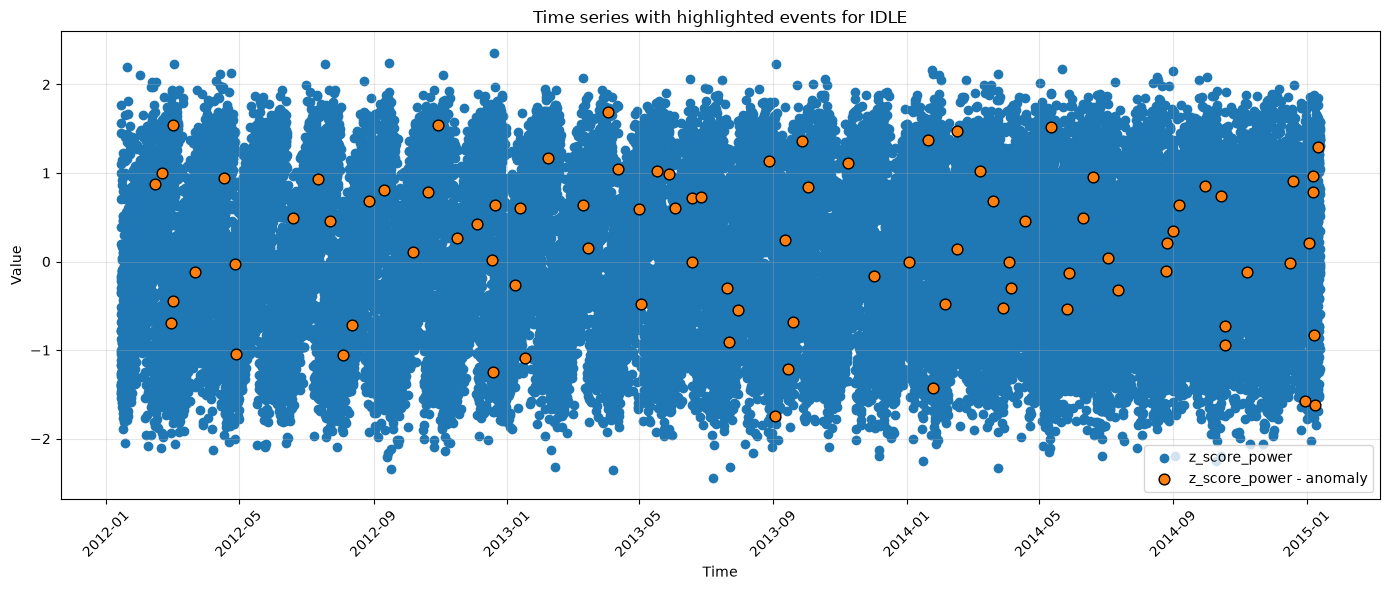

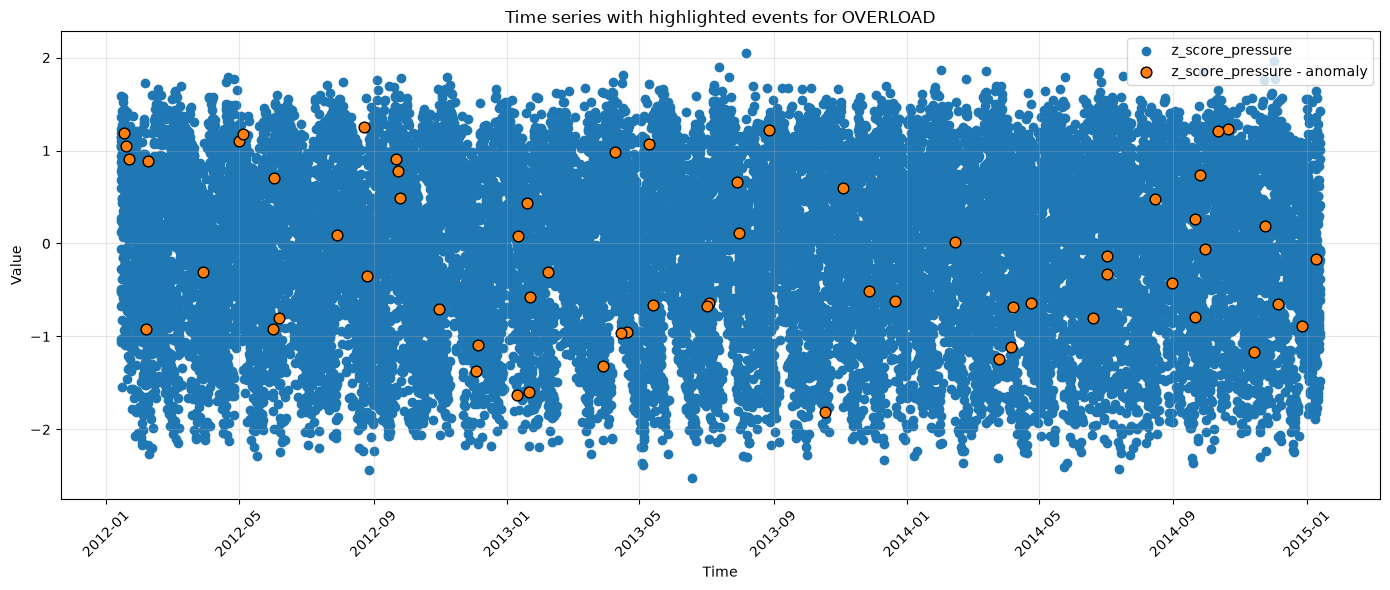

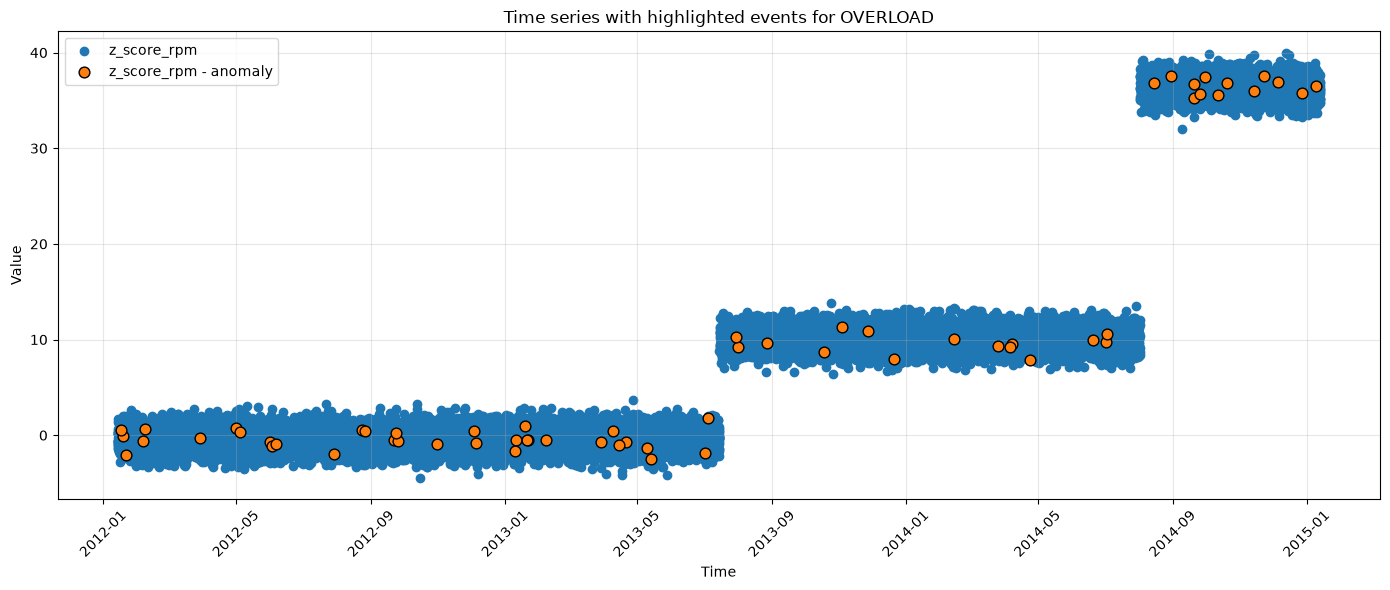

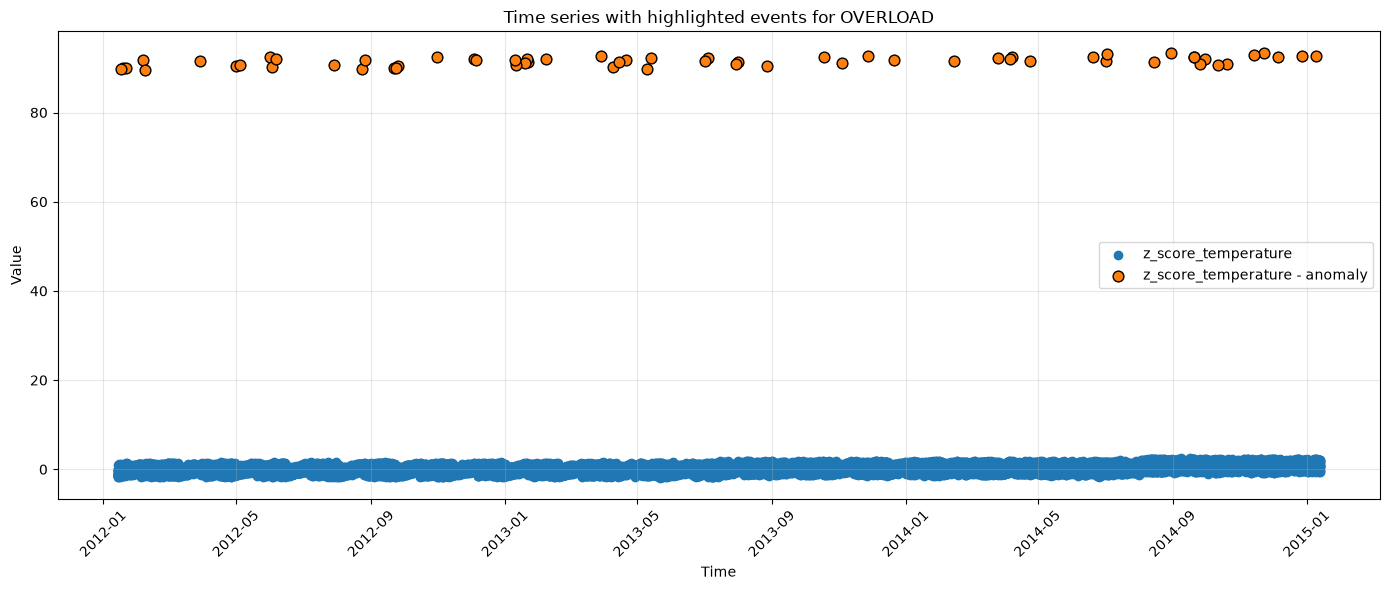

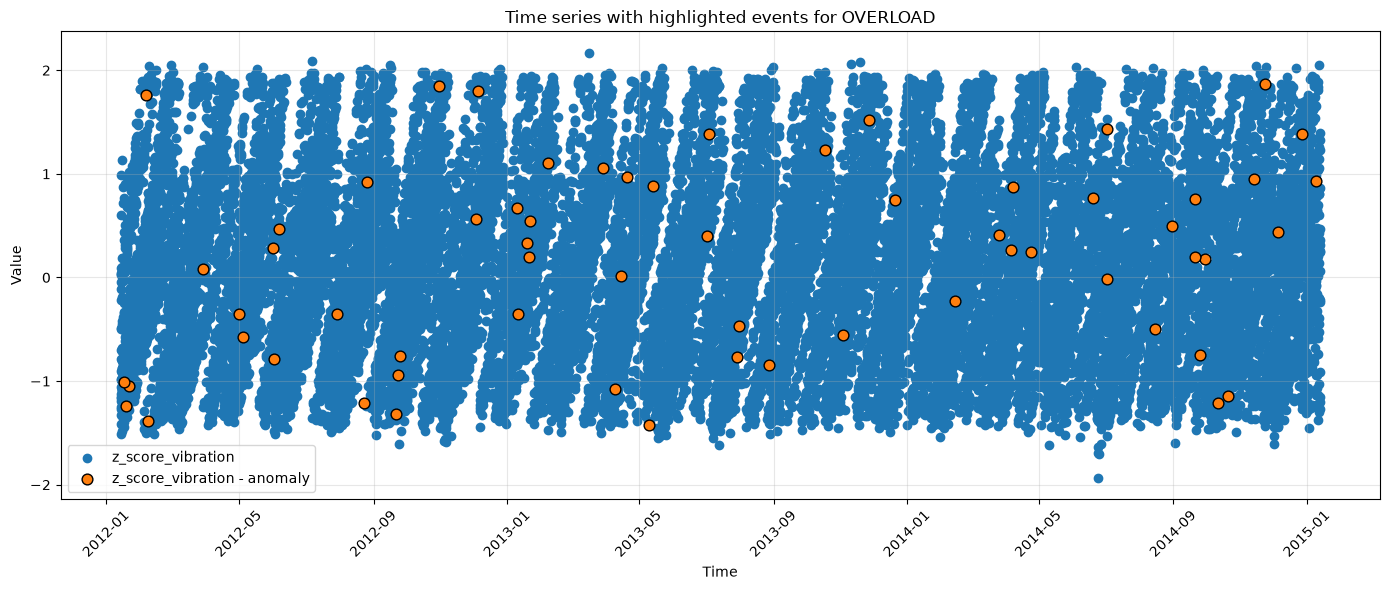

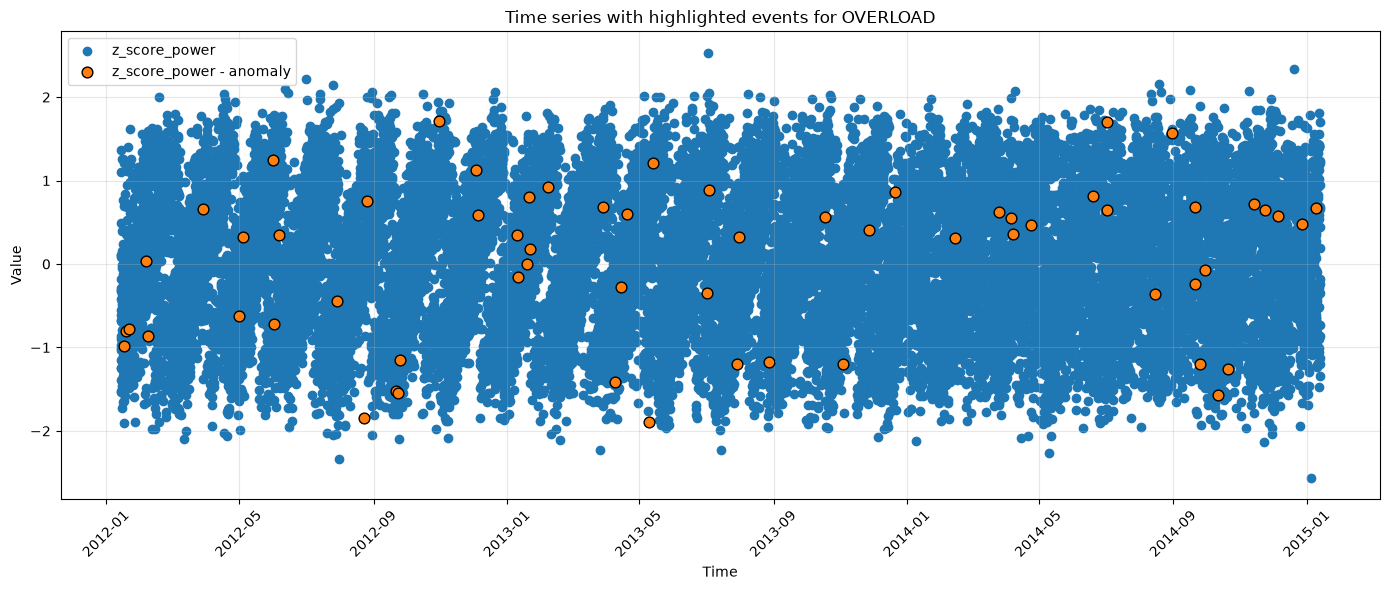

In [25]:
from c1_sensor_quality.anomaly_detector.constants import OPERATING_MODES
import matplotlib.pyplot as plt


# Colonnes à tracer
columns = [f"z_score_{sensor}" for sensor in SENSORS]
OPERATING_MODES
# Condition pour identifier les points à surligner
mask = out['anomaly_type'] == 'sensor_spike'
for op in OPERATING_MODES:
    for col in columns:
        fig, ax = plt.subplots(figsize=(14, 6))

        # Courbe continue
        ax.scatter(out[out["operating_mode"]==op]['timestamp'], out[out["operating_mode"]==op][col], label=col)

        # Points à mettre en évidence
        ax.scatter(
            out[out["operating_mode"]==op].loc[mask, 'timestamp'],
            out[out["operating_mode"]==op].loc[mask, col],
            s=60,
            edgecolors='black',
            zorder=3,
            label=f'{col} - anomaly'
        )

        ax.set_xlabel('Time')
        ax.set_ylabel('Value')
        ax.set_title(f'Time series with highlighted events for {op}')
        ax.legend()
        ax.grid(alpha=0.3)

        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

In [46]:
out[out["z_score_temperature"]>80]["anomaly_type"].value_counts()

anomaly_type
sensor_spike    1061
Name: count, dtype: int64

In [47]:
out["anomaly_type"].value_counts()

anomaly_type
normal           522395
sensor_frozen      1068
sensor_spike       1061
Name: count, dtype: int64

In [2]:
import sys
from pathlib import Path

import pandas as pd


def find_repo_root(start: Path) -> Path:
    """Walk up from ``start`` until the repository root is found."""
    for base in (start, *start.parents):
        if (base / "pyproject.toml").is_file() and (base / "data").is_dir():
            return base
    raise FileNotFoundError(
        f"Repository root not found from {start}. Open the notebook from inside the repository."
    )

# This notebook lives in notebooks/, so resolve paths from the repository root.
REPO_ROOT = find_repo_root(Path.cwd())

# The split lives in the C1 service. Make it importable even when the
# notebook runs on an interpreter where the workspace package is not installed.
SERVICE_SRC = REPO_ROOT / "services/c1-sensor-quality/src"
if str(SERVICE_SRC) not in sys.path:
    sys.path.insert(0, str(SERVICE_SRC))

from c1_sensor_quality.anomaly_detector.main import detect_anomaly

In [43]:
input = pd.DataFrame([{
    "timestamp": "2012-01-14 00:00:00",
    "machine_id": "M001",
    "operating_mode": "HIGH_LOAD",
    "temperature": 46.07525961240461,
    "vibration": 1.6468395553300161,
    "pressure": 98.80059671285558,
    "rpm": 2188.426973215657,
    "power": 316.1677083408033,
    "anomaly": False,
    "anomaly_type": "normal",
    "failure_probability_gt": 0.03687056876971417,
    "failure_in_7_days": False,
    "remaining_useful_life_hours": 963.0,
    "failure_type": "motor_imbalance",
    "important_features": "vibration,rpm",
    "maintenance_action": "align_motor",
    "priority": "low",
    "concept_drift_active": False,
    "quality_disposition": "valid",
    "quality_flags": "none"
},{
    "timestamp": "2012-01-14 00:00:00",
    "machine_id": "M001",
    "operating_mode": "HIGH_LOAD",
    "temperature": 82.07525961240461,
    "vibration": 1.0,
    "pressure": 98.80059671285558,
    "rpm": 2188.426973215657,
    "power": 316.1677083408033,
    "anomaly": False,
    "anomaly_type": "normal",
    "failure_probability_gt": 0.03687056876971417,
    "failure_in_7_days": False,
    "remaining_useful_life_hours": 963.0,
    "failure_type": "motor_imbalance",
    "important_features": "vibration,rpm",
    "maintenance_action": "align_motor",
    "priority": "low",
    "concept_drift_active": False,
    "quality_disposition": "valid",
    "quality_flags": "none"
}])

In [44]:
input.head()

,timestamp,machine_id,operating_mode,temperature,vibration,pressure,rpm,power,anomaly,anomaly_type,failure_probability_gt,failure_in_7_days,remaining_useful_life_hours,failure_type,important_features,maintenance_action,priority,concept_drift_active,quality_disposition,quality_flags
0,2012-01-14 00:00:00,M001,HIGH_LOAD,46.07526,1.64684,98.800597,2188.426973,316.167708,False,normal,0.036871,False,963.0,motor_imbalance,"vibration,rpm",align_motor,low,False,valid,none
1,2012-01-14 00:00:00,M001,HIGH_LOAD,82.07526,1.00000,98.800597,2188.426973,316.167708,False,normal,0.036871,False,963.0,motor_imbalance,"vibration,rpm",align_motor,low,False,valid,none


In [45]:
preds = detect_anomaly(input)

In [46]:
preds.head()

,anomaly_type,anomaly_confidence,probability_normal,probability_sensor_frozen,probability_sensor_spike
0,normal,0.73,0.73,0.27,0.0
1,sensor_frozen,0.70,0.30,0.70,0.0


In [47]:
(preds["anomaly_confidence"]>0.71).any()

np.True_

In [48]:
preds.loc[preds["anomaly_confidence"]>0.71].index


RangeIndex(start=0, stop=1, step=1)

In [51]:
preds.iloc[preds.loc[preds["anomaly_confidence"]>0.71].index]

,anomaly_type,anomaly_confidence,probability_normal,probability_sensor_frozen,probability_sensor_spike
0,normal,0.73,0.73,0.27,0.0


In [37]:
if (preds["anomaly_confidence"]>0.5).any():
    print("in")

in


In [53]:
preds.shape[0]

2